# Reference build: whom should Kalpa call before October's due date?

TRAINER. The full solution of Build 2 and the solution twin of the starter repository's breadcrumb
notebook, section for section. It runs cold, top to bottom, in about two minutes on a Codespace, and
every card's number prints as a PASS check against `docs/detailing/W06_research/W06_datasets.md`
section 3(c), or as a printed difference with its reason.

**Who needs the answer.** The trainer and the two TAs, at Wednesday's checkpoint, Thursday's
approach gate and Saturday's questions. When a group's number differs from the one here, this
notebook tells you whether the group or the method is wrong.

**The questions on the way.** Can we trust the rows? What is decided, from what is known when? What
must the system do? Does a model beat the simple rule? What is the error bill at 5 to 1? Where does
the score live? What can a POC on Taiwan's book never prove? What does each card, and each twist,
change?

## 0. What does the notebook need before it starts?

The setup cell imports the tools, fixes Rohan's cost units (a wasted call is 1, a missed default
is 5) and the split, and defines three helpers: `check()` prints PASS or FAIL without stopping the
run, `near()` compares a measured number with the research number within a stated tolerance, and
`ladder()` draws the week's eight stages with the current one lit. Reading the `.xls` file needs the
`xlrd` package.

In [1]:
# Tools, Rohan's cost units, the split, and three small helpers.
import io, time, zipfile, pathlib, urllib.request, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score
import xlrd  # pandas needs it to read the .xls file; pip install xlrd if this line fails
warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "font.size": 11, "axes.spines.top": False, "axes.spines.right": False})

COST_WASTED, COST_MISSED = 1, 5        # Rohan's units: a wasted call is 1, a missed default is 5
SEED, TEST_SHARE = 42, 0.3             # the week's split: 21,000 to learn from, 9,000 to test on
TARGET = "default payment next month"

TALLY = {"PASS": 0, "FAIL": 0}
def check(label, ok, detail=""):
    word = "PASS" if ok else "FAIL"
    TALLY[word] += 1
    print(f"{word}  {label}" + (f"  ({detail})" if detail else ""))

def near(value, expected, tol):
    return abs(value - expected) <= tol

STAGES = ["0 Business", "1 Frame", "2 Requirements", "3 Options", "4 POC", "5 Architecture", "6 MVP slice", "7 Defend"]
def ladder(lit, title):
    """The week's eight stages as one strip, with the stage this section serves drawn dark."""
    fig, ax = plt.subplots(figsize=(11, 1.25))
    for i, name in enumerate(STAGES):
        dark = i == lit
        ax.add_patch(FancyBboxPatch((i * 1.35, 0), 1.2, 0.8, boxstyle="round,pad=0.02,rounding_size=0.08",
                                    fc="#2B2253" if dark else "#EEEAF7", ec="#5B4BA5", lw=1.2))
        ax.text(i * 1.35 + 0.6, 0.4, name.replace(" ", "\n", 1), ha="center", va="center", fontsize=10,
                color="white" if dark else "#2B2253", fontweight="bold" if dark else "normal")
    ax.set_xlim(-0.1, 8 * 1.35); ax.set_ylim(-0.1, 0.9); ax.axis("off")
    ax.set_title(title, fontsize=11, loc="left")
    plt.show()

print("ready: pandas", pd.__version__, "| scikit-learn", sklearn.__version__, "| xlrd", xlrd.__version__)

ready: pandas 3.0.5 | scikit-learn 1.9.1 | xlrd 2.0.2


In [2]:
# The numbers W06_datasets.md section 3(c) measured on 29 October 2026. Every card below checks against them.
EXPECTED = {
    "rows": 30000, "defaults": 6636, "base_rate": 0.2212,
    "sept_undocumented": 17496, "edu_odd": 345, "marriage_zero": 54,
    "zero_accounts": 795, "zero_accounts_default": 299, "exact_dupes": 35, "dupe_group_rows": 108, "dupe_conflicts": 21,
    "neg_bills": 590, "over_limit": 2115,
    "c1_threshold": 0.16, "c1_cost_tuned": 568, "c1_cost_half": 762, "c1_share_tuned": 0.445, "c1_share_half": 0.114,
    "cost_everyone": 779, "cost_nobody": 1106,
    "c1_twist_threshold": 1 / 21, "c1_twist_cost": 765, "c1_twist_share": 0.977,
    "c2_model_1000": 687, "c2_rule_1000": 666, "c2_model_2000": 1079, "c2_rule_2000": 1010,
    "c3_pbill_share": 0.628, "c3_p_share": 0.427, "c3_pbill_defaulters": 469, "c3_p_defaulters": 676,
    "c4_lr_onehot": 0.765, "c4_hgb": 0.778, "c4_lr_raw": 0.717,
    "c5_auc_with": 0.7779, "c5_auc_without": 0.7769,
    "c6_auc_lag": 0.747, "c6_model_1000": 614, "c6_rule_1000": 563,
    "c7_proxy_auc": 0.747, "c7_proxy_1000": 539, "c7_true_auc": 0.779, "c7_true_1000": 680,
    "c8_base_relabel": 0.211, "c8_base_removed": 0.217,
}
print(len(EXPECTED), "research numbers loaded")

45 research numbers loaded


## 1. Stage 1, the frame: can we trust the rows, and what is decided?

**Who needs the answer.** Rohan, before he trusts any list, and every group at Tuesday's paper
frame. A group that skips this section builds on a file it has misread.

**The questions on the way.** How is the file read? What share of the book defaulted? Which values
does the data dictionary not explain? Which rows repeat? What exactly is decided, from what is
known when?

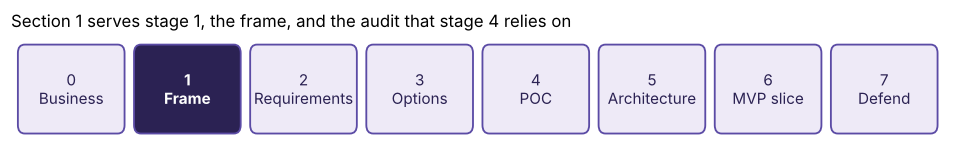

In [3]:
ladder(1, "Section 1 serves stage 1, the frame, and the audit that stage 4 relies on")

### How is the file read, and what does the hurried read get wrong?

The workbook keeps two header rows: the first holds X1 to X23 and Y, and the real names sit on the
second. A hurried `read_excel` takes the first as the header and turns the real names into a row of
data, so every column becomes text and the book has 30,001 customers.

**Predict before you run.** With the default read, how many rows does pandas report? (a) 30,000
(b) 30,001 (c) 29,999

In [4]:
# Download once, keep a cached copy, and read the real names from the sheet's second row.
URL = "https://archive.ics.uci.edu/static/public/350/default+of+credit+card+clients.zip"  # verified 29 October 2026
def load_cards():
    f = pathlib.Path.home() / ".cache" / "c2_datasets" / "uci350" / "default of credit card clients.xls"
    if not f.exists():
        f.parent.mkdir(parents=True, exist_ok=True)
        with zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(URL, timeout=120).read())) as z:
            f.write_bytes(z.read("default of credit card clients.xls"))
    return f

XLS = load_cards()
wrong = pd.read_excel(XLS)              # the hurried read
cards = pd.read_excel(XLS, header=1)    # the right read
print("hurried read:", wrong.shape, "| first columns", list(wrong.columns[:4]), "| first row", list(wrong.iloc[0, :4]))
print("right read:  ", cards.shape, "| first columns", list(cards.columns[:4]))

hurried read: (30001, 25) | first columns ['Unnamed: 0', 'X1', 'X2', 'X3'] | first row ['ID', 'LIMIT_BAL', 'SEX', 'EDUCATION']
right read:   (30000, 25) | first columns ['ID', 'LIMIT_BAL', 'SEX', 'EDUCATION']


**What happened.** The answer is (b). The hurried read reports 30,001 rows and a first row that is
the real header; the right read reports 30,000 customers and 25 columns.

In [5]:
check("the right read has 30,000 customers and 25 columns", cards.shape == (EXPECTED["rows"], 25))
check("the hurried read has one extra row and text columns", len(wrong) == 30001 and wrong["X1"].dtype == object)
n_def = int(cards[TARGET].sum()); base = cards[TARGET].mean()
check("6,636 defaulted in October, a base rate of 22.12 percent", n_def == EXPECTED["defaults"] and near(base, EXPECTED["base_rate"], 0.0001),
      f"{n_def:,} of {len(cards):,} = {base:.4f}")

PASS  the right read has 30,000 customers and 25 columns
PASS  the hurried read has one extra row and text columns
PASS  6,636 defaulted in October, a base rate of 22.12 percent  (6,636 of 30,000 = 0.2212)


### What share defaulted, and does last month's lateness already say much?

The base rate is the first passport number. The second panel shows why "sort by months late" is a
serious rival: September's status already separates the book, and the model has to beat that.

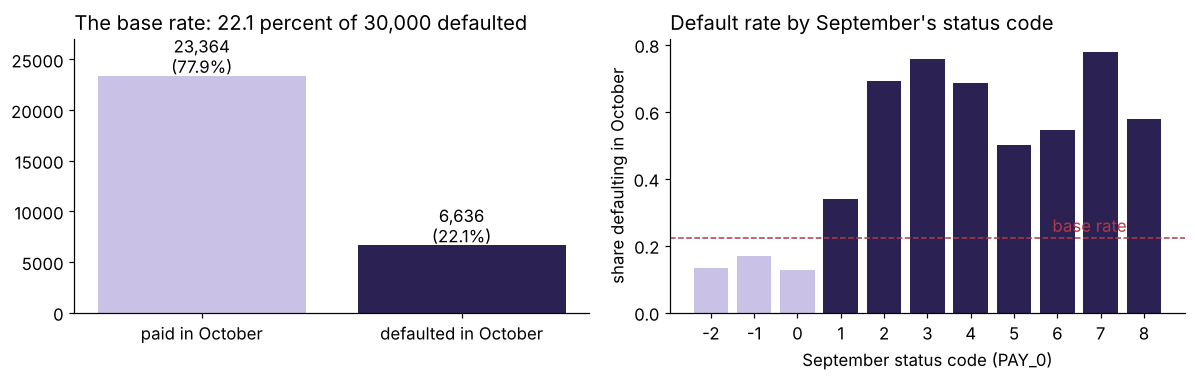

In [6]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.6))
counts = cards[TARGET].value_counts().sort_index()
a1.bar(["paid in October", "defaulted in October"], counts.values, color=["#C9C2E6", "#2B2253"])
for i, v in enumerate(counts.values):
    a1.text(i, v + 300, f"{v:,}\n({v / len(cards):.1%})", ha="center", fontsize=11)
a1.set_ylim(0, 27000); a1.set_title("The base rate: 22.1 percent of 30,000 defaulted", loc="left")
rate = cards.groupby("PAY_0")[TARGET].agg(["mean", "size"])
a2.bar(rate.index.astype(str), rate["mean"], color=["#C9C2E6" if s < 1 else "#2B2253" for s in rate.index])
a2.axhline(base, color="#B23A48", ls="--", lw=1); a2.text(9.6, base + 0.02, "base rate", color="#B23A48", ha="right")
a2.set_xlabel("September status code (PAY_0)"); a2.set_ylabel("share defaulting in October")
a2.set_title("Default rate by September's status code", loc="left")
plt.tight_layout(); plt.show()

### Which values does the data dictionary not explain, and which rows repeat?

The UCI page defines the status codes as -1 for "pay duly" and 1 to 9 for months of delay, education
as 1 to 4 and marital status as 1 to 3 (read on the page, 29 October 2026). This cell measures every
real trap the research found, so a TA can tell a group how close it came. None of these is named in
a STUDENT file; the room finds them by sorting and reconciling.

In [7]:
STATUS = ["PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]
BILLS = [f"BILL_AMT{i}" for i in range(1, 7)]
PAYS = [f"PAY_AMT{i}" for i in range(1, 7)]
INPUTS = [c for c in cards.columns if c not in ("ID", TARGET)]

sept_odd = int(cards["PAY_0"].isin([-2, 0]).sum())
code1 = [int((cards[c] == 1).sum()) for c in STATUS]
edu_odd = int(cards["EDUCATION"].isin([0, 5, 6]).sum())
mar_odd = int((cards["MARRIAGE"] == 0).sum())
zero = (cards[BILLS] == 0).all(axis=1) & (cards[PAYS] == 0).all(axis=1)
zero_def = int(cards.loc[zero, TARGET].sum())
exact = int(cards.duplicated(subset=INPUTS + [TARGET]).sum())
grp = cards[cards.duplicated(subset=INPUTS, keep=False)]
conflicts = int(grp.groupby(INPUTS)[TARGET].nunique().gt(1).sum())
neg = int((cards["BILL_AMT1"] < 0).sum()); over = int((cards["BILL_AMT1"] > cards["LIMIT_BAL"]).sum())

audit = pd.DataFrame([
    ["Two header rows", "the whole sheet", "read with header=1", "the real names sit on row two"],
    ["PAY_0 is September; there is no PAY_1", "6 status columns", "keep the names, map months by meaning", "suffix 1 means September for bills and payments"],
    ["Status codes -2 and 0, absent from the dictionary", f"{sept_odd:,} September values ({sept_odd / len(cards):.1%})", "keep as categories; ask Rohan's data team", "a guess at their meaning is a guess at the label"],
    ["Code 1 used in September only", "counts by month " + ", ".join(map(str, code1)), "rules read September alone", "the months were not coded alike"],
    ["Education 0, 5, 6 and marital status 0", f"{edu_odd} and {mar_odd} rows", "keep as their own categories; ask", "too few rows to matter, too odd to guess"],
    ["Accounts owing nothing for six months", f"{int(zero.sum())} accounts, {zero_def} labelled default ({zero_def / zero.sum():.1%})", "keep the labels; ask Rohan (card 8)", "a default with nothing owed needs a ruling, never a guess"],
    ["Repeated rows", f"{exact} exact repeats; {len(grp)} rows share inputs; {conflicts} groups disagree on the label", "keep all 30,000; measured below", "the 9,000-customer test book stays the one card 2 names"],
    ["Negative and over-limit September bills", f"{neg} below zero, {over:,} above the limit", "keep; clip at zero only when ranking by balance", "a credit balance and an over-limit balance are real states"],
], columns=["What the audit finds", "How many", "What the reference build does", "Why"])
display(audit)

,What the audit finds,How many,What the reference build does,Why
0,Two header rows,the whole sheet,read with header=1,the real names sit on row two
1,PAY_0 is September; there is no PAY_1,6 status columns,"keep the names, map months by meaning",suffix 1 means September for bills and payments
2,"Status codes -2 and 0, absent from the dictionary","17,496 September values (58.3%)",keep as categories; ask Rohan's data team,a guess at their meaning is a guess at the label
3,Code 1 used in September only,"counts by month 3688, 28, 4, 2, 0, 0",rules read September alone,the months were not coded alike
4,"Education 0, 5, 6 and marital status 0",345 and 54 rows,keep as their own categories; ask,"too few rows to matter, too odd to guess"
5,Accounts owing nothing for six months,"795 accounts, 299 labelled default (37.6%)",keep the labels; ask Rohan (card 8),"a default with nothing owed needs a ruling, ne..."
6,Repeated rows,35 exact repeats; 108 rows share inputs; 21 gr...,"keep all 30,000; measured below","the 9,000-customer test book stays the one car..."
7,Negative and over-limit September bills,"590 below zero, 2,115 above the limit",keep; clip at zero only when ranking by balance,a credit balance and an over-limit balance are...


In [8]:
check("17,496 September statuses use -2 or 0", sept_odd == EXPECTED["sept_undocumented"])
check("code 1 appears 3,688 times in September and almost never after", code1[0] == 3688 and sum(code1[1:]) == 34, str(code1))
check("345 education codes and 54 marital codes sit outside the dictionary", edu_odd == EXPECTED["edu_odd"] and mar_odd == EXPECTED["marriage_zero"])
check("795 accounts owe nothing for six months and 299 of them are labelled default",
      int(zero.sum()) == EXPECTED["zero_accounts"] and zero_def == EXPECTED["zero_accounts_default"])
check("35 exact repeats, 108 rows sharing inputs, 21 groups with conflicting labels",
      exact == EXPECTED["exact_dupes"] and len(grp) == EXPECTED["dupe_group_rows"] and conflicts == EXPECTED["dupe_conflicts"])
check("590 negative and 2,115 over-limit September bills", neg == EXPECTED["neg_bills"] and over == EXPECTED["over_limit"])

PASS  17,496 September statuses use -2 or 0
PASS  code 1 appears 3,688 times in September and almost never after  ([3688, 28, 4, 2, 0, 0])
PASS  345 education codes and 54 marital codes sit outside the dictionary
PASS  795 accounts owe nothing for six months and 299 of them are labelled default
PASS  35 exact repeats, 108 rows sharing inputs, 21 groups with conflicting labels
PASS  590 negative and 2,115 over-limit September bills


### What exactly is decided, from what is known when?

This is the reference answer to workbook page 2. Every input is known by the end of September,
which is before October's due date; the outcome is known only after that date passes.

In [9]:
frame = pd.DataFrame([
    ["What is decided", "whether Kalpa's team calls this cardholder before October's due date"],
    ["About whom, how often", "one cardholder, once, for October"],
    ["Known on the day of the list", "limit, profile, and six months of status, bill and payment, April to September 2005"],
    ["Not known yet", "whether the cardholder pays in October"],
    ["The outcome predicted", "default payment next month: 1 if the cardholder defaults in October"],
    ["How often it happens", f"{base:.1%} of the book, {n_def:,} of {len(cards):,}"],
    ["The one action", "a call; nothing else changes"],
    ["What each error costs", f"a wasted call {COST_WASTED} unit, a missed default {COST_MISSED} units"],
], columns=["Frame question", "Kalpa's answer"])
display(frame)
check("the frame names a single action and both error costs", COST_MISSED / COST_WASTED == 5)

,Frame question,Kalpa's answer
0,What is decided,whether Kalpa's team calls this cardholder bef...
1,"About whom, how often","one cardholder, once, for October"
2,Known on the day of the list,"limit, profile, and six months of status, bill..."
3,Not known yet,whether the cardholder pays in October
4,The outcome predicted,default payment next month: 1 if the cardholde...
5,How often it happens,"22.1% of the book, 6,636 of 30,000"
6,The one action,a call; nothing else changes
7,What each error costs,"a wasted call 1 unit, a missed default 5 units"


PASS  the frame names a single action and both error costs


## 2. Stage 2, requirements: what must the system do, and what may it never do?

**Who needs the answer.** Rohan and Kalpa's compliance team: a list nobody can explain, or one
built from data the team may not use, is refused however good its bill.

**The questions on the way.** Which requirement is a function, which a quality, which a limit? Is
every input known before the list is built? Does the target leak into the inputs?

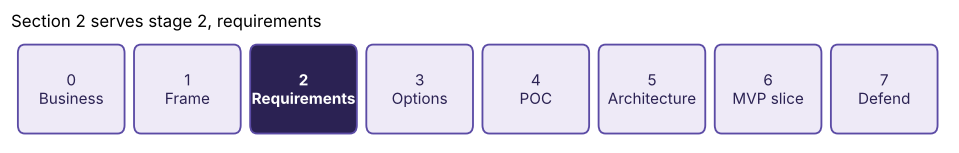

,Kind,Reference answer for workbook page 3
0,Functional,"On list day, return the call list sized to the..."
1,Non-functional,"Scores the 9,000-customer book in under a minu..."
2,Constraint,"Costs in units, 1 to 5; one action, a call; on..."
3,Security,No customer data in the repository (downloaded...
4,Privacy,"No names or phone numbers in the POC; sex, mar..."
5,Governance,A model card; Rohan signs the list off; a name...


In [10]:
ladder(2, "Section 2 serves stage 2, requirements")
reqs = pd.DataFrame([
    ["Functional", "On list day, return the call list sized to the team, each row with the cardholder, the chance, the main reason and the cost of not calling."],
    ["Non-functional", "Scores the 9,000-customer book in under a minute on a laptop; the same input gives the same list; the bill is measured on a test book used once."],
    ["Constraint", "Costs in units, 1 to 5; one action, a call; only data known before the list; the group's card."],
    ["Security", "No customer data in the repository (downloaded in code); the list goes only to the collections team and risk."],
    ["Privacy", "No names or phone numbers in the POC; sex, marital status, age and education used only where the card allows, and outcomes checked by group either way."],
    ["Governance", "A model card; Rohan signs the list off; a named person can stop it; a written reason per call where card 4 applies."],
], columns=["Kind", "Reference answer for workbook page 3"])
display(reqs)

In [11]:
# Requirement checks a group can run: the target and the ID never feed the model, and every input exists before the list.
# The month each input is written, from the UCI page: suffix 1 (and PAY_0) is September 2005, suffix 6 is April.
MONTH_OF = {c: 0 for c in ["LIMIT_BAL", "SEX", "EDUCATION", "MARRIAGE", "AGE"]}     # known when the account opened
MONTH_OF.update({c: m for c, m in zip(STATUS, [9, 8, 7, 6, 5, 4])})
MONTH_OF.update({f"{kind}{i}": 10 - i for kind in ("BILL_AMT", "PAY_AMT") for i in range(1, 7)})
check("the target is never an input", TARGET not in INPUTS)
check("the row ID is never an input", "ID" not in INPUTS)
check("every one of the 23 inputs is written by September, before October's due date",
      set(MONTH_OF) == set(INPUTS) and max(MONTH_OF.values()) == 9, f"latest month {max(MONTH_OF.values())}")

PASS  the target is never an input
PASS  the row ID is never an input
PASS  every one of the 23 inputs is written by September, before October's due date  (latest month 9)


## 3. Stage 3, options: does a model beat the simple rule?

**Who needs the answer.** Rohan, who will pay for a model only if it beats what his team could do
with a sort in a spreadsheet, and every group's A against B sheet.

**The questions on the way.** How is the book split? How good is "sort by months late"? What does
a logistic regression score, and what does it score when the status codes are read as numbers?
What does gradient boosting add?

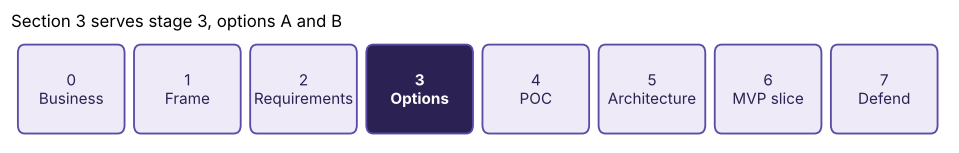

train 21000 | test 9000 | fit 15750 | validation 5250
PASS  the test book holds 9,000 cardholders at the same base rate  (0.2212)


In [12]:
ladder(3, "Section 3 serves stage 3, options A and B")
X = cards[INPUTS]; y = cards[TARGET].to_numpy()
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=TEST_SHARE, random_state=SEED, stratify=y)
X_fit, X_val, y_fit, y_val = train_test_split(X_train, y_train, test_size=0.25, random_state=SEED, stratify=y_train)
print("train", len(X_train), "| test", len(X_test), "| fit", len(X_fit), "| validation", len(X_val))
check("the test book holds 9,000 cardholders at the same base rate", len(X_test) == 9000 and near(y_test.mean(), EXPECTED["base_rate"], 0.0005),
      f"{y_test.mean():.4f}")

### Approach A: how far does "sort by months late in September" go?

As a flag, the rule calls everyone one month or more late in September; as a ranking, it sorts by
September's status and breaks ties at random.

In [13]:
def flag_stats(flag, truth):
    tp = int((flag & (truth == 1)).sum()); fp = int((flag & (truth == 0)).sum()); fn = int((~flag & (truth == 1)).sum())
    return flag.mean(), tp / (tp + fp), tp / (tp + fn)

for k in (1, 2):
    share, prec, rec = flag_stats((X_test["PAY_0"] >= k).to_numpy(), y_test)
    print(f"rule 'September status {k} or worse': calls {share:.1%} of the book, precision {prec:.3f}, recall {rec:.3f}")
s1 = flag_stats((X_test["PAY_0"] >= 1).to_numpy(), y_test); s2 = flag_stats((X_test["PAY_0"] >= 2).to_numpy(), y_test)
check("status 1 or worse: precision 0.50, recall 0.50", near(s1[1], 0.50, 0.005) and near(s1[2], 0.50, 0.005))
check("status 2 or worse: precision 0.69, recall 0.32", near(s2[1], 0.69, 0.005) and near(s2[2], 0.32, 0.005))

rule 'September status 1 or worse': calls 22.3% of the book, precision 0.499, recall 0.503
rule 'September status 2 or worse': calls 10.4% of the book, precision 0.690, recall 0.324
PASS  status 1 or worse: precision 0.50, recall 0.50
PASS  status 2 or worse: precision 0.69, recall 0.32


### Approach B: what do the two models score, and what is the trap?

**Predict before you run.** A logistic regression reads September's status as a number on a line,
so -2 counts as "better" than -1, which counts as "better" than 0. Will that cost it more or less
than switching to gradient boosting gains?

In [14]:
CAT = STATUS + ["EDUCATION", "MARRIAGE", "SEX"]
NUM = [c for c in INPUTS if c not in CAT]
def lr_raw():
    return make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
def lr_onehot():
    ct = ColumnTransformer([("c", OneHotEncoder(handle_unknown="ignore"), CAT), ("n", StandardScaler(), NUM)])
    return make_pipeline(ct, LogisticRegression(max_iter=3000))
def hgb():
    return HistGradientBoostingClassifier(random_state=0, max_iter=300, learning_rate=0.05)

t0 = time.time()
m_raw = lr_raw().fit(X_train, y_train); p_raw = m_raw.predict_proba(X_test)[:, 1]
m_lr = lr_onehot().fit(X_train, y_train); p_lr = m_lr.predict_proba(X_test)[:, 1]
m_hg = hgb().fit(X_train, y_train); p_hg = m_hg.predict_proba(X_test)[:, 1]
auc = {name: roc_auc_score(y_test, p) for name, p in [("logistic, codes as numbers", p_raw), ("logistic, codes as categories", p_lr), ("gradient boosting", p_hg)]}
for k, v in auc.items():
    print(f"{k:32s} AUC {v:.4f}")
print(f"three fits in {time.time() - t0:.1f} seconds")

logistic, codes as numbers       AUC 0.7150
logistic, codes as categories    AUC 0.7629
gradient boosting                AUC 0.7789
three fits in 1.1 seconds


**What happened.** Reading the codes as numbers costs the logistic regression about 0.05 of AUC
(0.715 against 0.763); switching to gradient boosting gains about 0.016 more (0.779). Coding the
statuses right is worth more than the choice of model, which is card 4's lesson.

In [15]:
check("seed 42: logistic with codes as numbers scores about 0.715", near(auc["logistic, codes as numbers"], 0.715, 0.002))
check("seed 42: logistic with codes as categories scores about 0.763", near(auc["logistic, codes as categories"], 0.763, 0.002))
check("seed 42: gradient boosting scores about 0.779", near(auc["gradient boosting"], 0.779, 0.002))

PASS  seed 42: logistic with codes as numbers scores about 0.715
PASS  seed 42: logistic with codes as categories scores about 0.763
PASS  seed 42: gradient boosting scores about 0.779


## 4. Stage 4, the POC: does the model beat doing nothing on the error bill?

**Who needs the answer.** Rohan's CFO, who prices the list in units, and the evaluator of every
group, who presents slides 4 and 5.

**The questions on the way.** What do the two simple lists cost? Which threshold do the costs set?
What does the default threshold of 0.5 cost? Does the answer hold on another split? What does
accuracy hide?

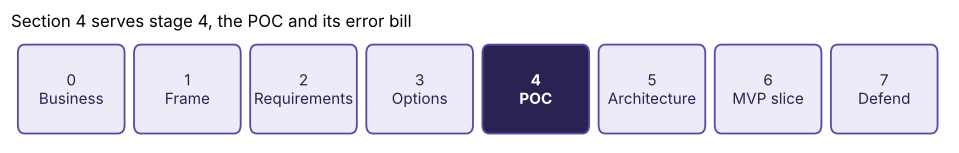

call nobody: 1106 units per 1,000 | call everyone: 779
PASS  calling nobody costs 1,106 units per 1,000 cardholders
PASS  calling everyone costs 779, so at 5 to 1 calling everyone already beats calling nobody


In [16]:
ladder(4, "Section 4 serves stage 4, the POC and its error bill")
def error_bill(truth, call, wasted=COST_WASTED, missed=COST_MISSED):
    """Cost units per 1,000 cardholders: wasted calls times their cost plus missed defaults times theirs."""
    call = np.asarray(call, bool); truth = np.asarray(truth)
    n_wasted = int((call & (truth == 0)).sum()); n_missed = int((~call & (truth == 1)).sum())
    return 1000 * (n_wasted * wasted + n_missed * missed) / len(truth)

bill_nobody = error_bill(y_test, np.zeros(len(y_test)))
bill_everyone = error_bill(y_test, np.ones(len(y_test)))
print(f"call nobody: {bill_nobody:.0f} units per 1,000 | call everyone: {bill_everyone:.0f}")
check("calling nobody costs 1,106 units per 1,000 cardholders", round(bill_nobody) == EXPECTED["cost_nobody"])
check("calling everyone costs 779, so at 5 to 1 calling everyone already beats calling nobody", round(bill_everyone) == EXPECTED["cost_everyone"])

### Which threshold do the costs set, and what does 0.5 cost?

Call a cardholder when the expected cost of not calling is larger than the expected cost of calling:
chance x 5 > (1 - chance) x 1, which gives chance > 1 / (1 + 5) = 0.167. The threshold is tuned on
the validation book with a model fitted on the remaining 15,750, then the test book is opened once.

In [17]:
m_hg2 = hgb().fit(X_fit, y_fit)
p_val = m_hg2.predict_proba(X_val)[:, 1]; p_te = m_hg2.predict_proba(X_test)[:, 1]
grid = np.linspace(0.01, 0.9, 179)
def tuned(ratio):
    bills = [((p_val < t) & (y_val == 1)).sum() * ratio + ((p_val >= t) & (y_val == 0)).sum() for t in grid]
    return float(grid[int(np.argmin(bills))])
THRESHOLD = tuned(COST_MISSED)
THEORY = COST_WASTED / (COST_WASTED + COST_MISSED)
for name, t in [("0.5, the default", 0.5), ("theory 1/6", THEORY), ("tuned on validation", THRESHOLD)]:
    print(f"threshold {name:22s} = {t:.3f}: calls {np.mean(p_te >= t):.1%}, bill {error_bill(y_test, p_te >= t):.0f} per 1,000")

threshold 0.5, the default       = 0.500: calls 11.4%, bill 762 per 1,000
threshold theory 1/6             = 0.167: calls 42.5%, bill 566 per 1,000
threshold tuned on validation    = 0.160: calls 44.5%, bill 568 per 1,000


In [18]:
bill_tuned = error_bill(y_test, p_te >= THRESHOLD); bill_half = error_bill(y_test, p_te >= 0.5)
check("the tuned threshold is 0.16, beside the theory's 0.167", near(THRESHOLD, EXPECTED["c1_threshold"], 0.006), f"{THRESHOLD:.3f}")
check("at 0.16 the list calls 44.5 percent and costs 568 per 1,000", near(np.mean(p_te >= THRESHOLD), EXPECTED["c1_share_tuned"], 0.002) and round(bill_tuned) == EXPECTED["c1_cost_tuned"])
check("at 0.5 the list calls 11.4 percent and costs 762, barely under calling everyone", round(bill_half) == EXPECTED["c1_cost_half"] and bill_half < bill_everyone)
rule_bill = error_bill(y_test, X_test["PAY_0"] >= 1)
check("the model at 0.16 beats rule A as a flag (status 1 or worse) by more than 50 units", bill_tuned < rule_bill - 50, f"{bill_tuned:.0f} against {rule_bill:.0f}")

PASS  the tuned threshold is 0.16, beside the theory's 0.167  (0.160)
PASS  at 0.16 the list calls 44.5 percent and costs 568 per 1,000
PASS  at 0.5 the list calls 11.4 percent and costs 762, barely under calling everyone
PASS  the model at 0.16 beats rule A as a flag (status 1 or worse) by more than 50 units  (568 against 661)


### What does the threshold sweep look like against the two simple lists?

The trap a hurried group shows is 0.5: its bill sits a whisker under "call everyone" and the group
concludes the model hardly helps. The sweep shows the bill falling to its floor near 0.16.

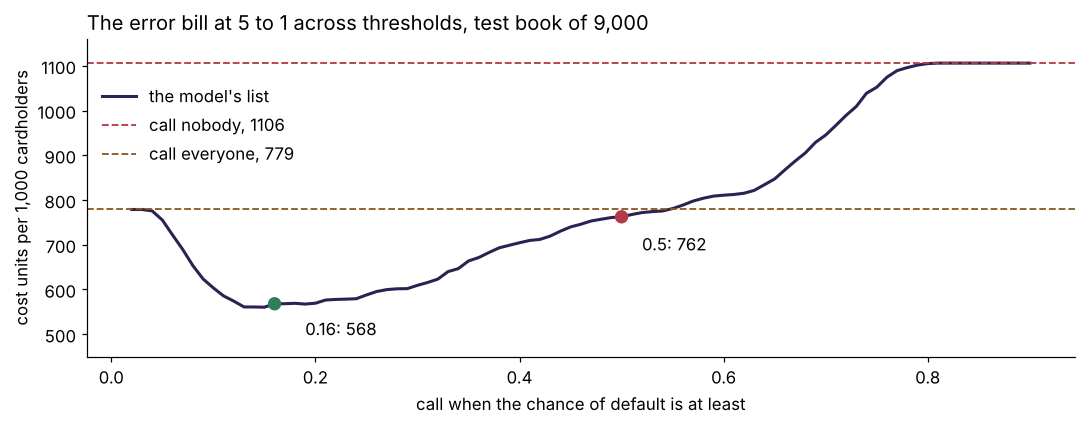

In [19]:
ts = np.linspace(0.02, 0.9, 89)
sweep = [error_bill(y_test, p_te >= t) for t in ts]
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(ts, sweep, color="#2B2253", lw=2, label="the model's list")
ax.axhline(bill_nobody, color="#B23A48", ls="--", lw=1.2, label=f"call nobody, {bill_nobody:.0f}")
ax.axhline(bill_everyone, color="#8A5A1F", ls="--", lw=1.2, label=f"call everyone, {bill_everyone:.0f}")
ax.scatter([0.5, THRESHOLD], [bill_half, bill_tuned], color=["#B23A48", "#2E7D5B"], zorder=3, s=60)
ax.annotate(f"0.5: {bill_half:.0f}", (0.5, bill_half), xytext=(0.52, bill_half - 75), fontsize=11)
ax.annotate(f"{THRESHOLD:.2f}: {bill_tuned:.0f}", (THRESHOLD, bill_tuned), xytext=(THRESHOLD + 0.03, bill_tuned - 70), fontsize=11)
ax.set_ylim(450, 1160)
ax.set_xlabel("call when the chance of default is at least"); ax.set_ylabel("cost units per 1,000 cardholders")
ax.set_title("The error bill at 5 to 1 across thresholds, test book of 9,000", loc="left")
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(0.0, 0.9)); plt.tight_layout(); plt.show()

### Does the answer hold on another split, and how do the model and the rule rank?

Five stratified splits (seeds 0 to 4) give the spread a group should quote on slide 5. The same loop
measures every five-split number cards 2, 4, 5 and 6 need, so the cards section reuses it.

In [20]:
LAG1 = [c for c in INPUTS if c not in ("PAY_0", "BILL_AMT1", "PAY_AMT1")]
SENSITIVE = ["SEX", "MARRIAGE", "AGE", "EDUCATION"]
NO_SENS = [c for c in INPUTS if c not in SENSITIVE]
def top_reach(truth, score, k):
    return int(truth[np.argsort(-score)[:k]].sum())

t0 = time.time(); rows = []
for seed in range(5):
    Xa, Xb, ya, yb = train_test_split(X, y, test_size=TEST_SHARE, random_state=seed, stratify=y)
    r = {"seed": seed}
    p = hgb().fit(Xa, ya).predict_proba(Xb)[:, 1]
    r["hgb_auc"] = roc_auc_score(yb, p); r["hgb_1000"] = top_reach(yb, p, 1000); r["hgb_2000"] = top_reach(yb, p, 2000)
    key = Xb["PAY_0"].to_numpy() + np.random.default_rng(seed).random(len(yb)) * 0.01
    r["rule_1000"] = top_reach(yb, key, 1000); r["rule_2000"] = top_reach(yb, key, 2000)
    r["lr_raw_auc"] = roc_auc_score(yb, lr_raw().fit(Xa, ya).predict_proba(Xb)[:, 1])
    r["lr_onehot_auc"] = roc_auc_score(yb, lr_onehot().fit(Xa, ya).predict_proba(Xb)[:, 1])
    r["nosens_auc"] = roc_auc_score(yb, hgb().fit(Xa[NO_SENS], ya).predict_proba(Xb[NO_SENS])[:, 1])
    pl = hgb().fit(Xa[LAG1], ya).predict_proba(Xb[LAG1])[:, 1]
    r["lag_auc"] = roc_auc_score(yb, pl); r["lag_1000"] = top_reach(yb, pl, 1000)
    key2 = Xb["PAY_2"].to_numpy() + np.random.default_rng(seed).random(len(yb)) * 0.01
    r["lag_rule_1000"] = top_reach(yb, key2, 1000)
    rows.append(r)
five = pd.DataFrame(rows).set_index("seed")
print(f"five splits in {time.time() - t0:.0f} seconds")
display(five.round(4))
FIVE = five.mean()
print("gradient boosting AUC across five splits:", f"mean {FIVE.hgb_auc:.4f}, from {five.hgb_auc.min():.4f} to {five.hgb_auc.max():.4f}")
check("five-split mean AUC of gradient boosting is 0.778, spread under 0.01", near(FIVE.hgb_auc, EXPECTED["c4_hgb"], 0.001) and five.hgb_auc.max() - five.hgb_auc.min() < 0.01)

five splits in 9 seconds


,hgb_auc,hgb_1000,hgb_2000,rule_1000,rule_2000,lr_raw_auc,lr_onehot_auc,nosens_auc,lag_auc,lag_1000,lag_rule_1000
seed,,,,,,,,,,,
0,0.7750,694,1067,670,1015,0.7145,0.7587,0.7747,0.7425,621,566
1,0.7809,683,1072,669,1009,0.7223,0.7705,0.7808,0.7532,615,563
2,0.7819,690,1093,662,1014,0.7198,0.7715,0.7796,0.7536,628,565
3,0.7770,695,1082,671,1016,0.7195,0.7629,0.7749,0.7419,613,562
4,0.7749,673,1081,658,995,0.7071,0.7606,0.7743,0.7444,591,560


gradient boosting AUC across five splits: mean 0.7779, from 0.7749 to 0.7819
PASS  five-split mean AUC of gradient boosting is 0.778, spread under 0.01


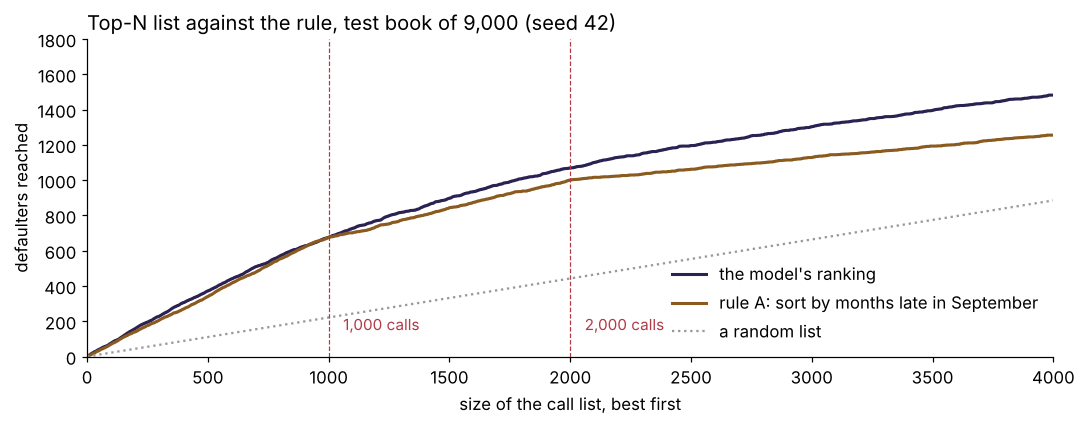

In [21]:
order = np.argsort(-p_hg)
rng = np.random.default_rng(0); rule_key = X_test["PAY_0"].to_numpy() + rng.random(len(y_test)) * 0.01
n = np.arange(1, len(y_test) + 1)
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(n, np.cumsum(y_test[order]), color="#2B2253", lw=2, label="the model's ranking")
ax.plot(n, np.cumsum(y_test[np.argsort(-rule_key)]), color="#8A5A1F", lw=2, label="rule A: sort by months late in September")
ax.plot(n, n * y_test.mean(), color="#999999", ls=":", lw=1.5, label="a random list")
for k in (1000, 2000):
    ax.axvline(k, color="#B23A48", lw=0.8, ls="--")
    ax.text(k + 60, 150, f"{k:,} calls", color="#B23A48", fontsize=10)
ax.set_xlim(0, 4000); ax.set_ylim(0, 1800)
ax.set_xlabel("size of the call list, best first"); ax.set_ylabel("defaulters reached")
ax.set_title("Top-N list against the rule, test book of 9,000 (seed 42)", loc="left")
ax.legend(frameon=False, loc="lower right"); plt.tight_layout(); plt.show()

### What does accuracy hide?

Predicting "no default" for everyone is right 77.9 percent of the time, and the model at 0.5 is
right 81.8 percent of the time. Accuracy prices a wasted call and a missed default the same, so it
cannot see the 5 to 1 ratio that drives the list.

In [22]:
acc_null = 1 - y_test.mean(); acc_model = ((p_hg >= 0.5) == y_test).mean()
print(f"accuracy, predict no default: {acc_null:.4f} | model at 0.5: {acc_model:.4f}")
check("predicting no default scores 77.9 percent accuracy and calls nobody", near(acc_null, 0.7788, 0.0001))
check("the most accurate cut is far from the cheapest cut", bill_half > bill_tuned + 150, f"{bill_half:.0f} against {bill_tuned:.0f}")

accuracy, predict no default: 0.7788 | model at 0.5: 0.8182
PASS  predicting no default scores 77.9 percent accuracy and calls nobody
PASS  the most accurate cut is far from the cheapest cut  (762 against 568)


## 5. Stage 5, the architecture: where does the score live, and what does one box do inside?

**Who needs the answer.** Kalpa's engineering lead, who has to run the list every month, and every
group at Thursday's gate, where page 6 is revised.

**The questions on the way.** What are the boxes between the data and the collections team? What
goes in and out of the score box? Does the score function give the same decision as the threshold?

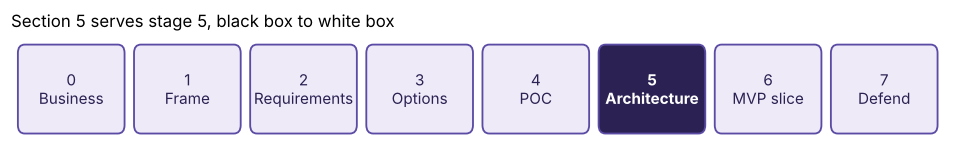

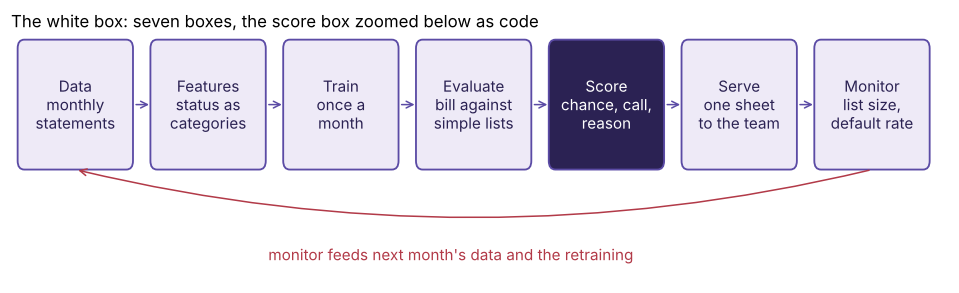

In [23]:
ladder(5, "Section 5 serves stage 5, black box to white box")
boxes = ["Data\nmonthly\nstatements", "Features\nstatus as\ncategories", "Train\nonce a\nmonth", "Evaluate\nbill against\nsimple lists",
         "Score\nchance, call,\nreason", "Serve\none sheet\nto the team", "Monitor\nlist size,\ndefault rate"]
fig, ax = plt.subplots(figsize=(11, 2.9))
for i, b in enumerate(boxes):
    lit = i == 4
    ax.add_patch(FancyBboxPatch((i * 1.6, 0.3), 1.35, 1.15, boxstyle="round,pad=0.02,rounding_size=0.08",
                                fc="#2B2253" if lit else "#EEEAF7", ec="#5B4BA5", lw=1.2))
    ax.text(i * 1.6 + 0.675, 0.875, b, ha="center", va="center", fontsize=10, color="white" if lit else "#2B2253")
    if i < len(boxes) - 1:
        ax.annotate("", xy=((i + 1) * 1.6, 0.875), xytext=(i * 1.6 + 1.37, 0.875), arrowprops=dict(arrowstyle="->", color="#5B4BA5"))
ax.annotate("", xy=(0.675, 0.28), xytext=(6 * 1.6 + 0.675, 0.28), arrowprops=dict(arrowstyle="->", color="#B23A48", connectionstyle="arc3,rad=-0.12"))
ax.text(5.2, -0.55, "monitor feeds next month's data and the retraining", color="#B23A48", ha="center", fontsize=10)
ax.set_xlim(-0.1, 7 * 1.6); ax.set_ylim(-0.75, 1.5); ax.axis("off")
ax.set_title("The white box: seven boxes, the score box zoomed below as code", loc="left", fontsize=11)
plt.show()

### What does the score box take in and give back?

This is the low-level design of the score box, and the function the live demo on slide 3 calls. It
takes one cardholder, returns the chance, the decision, the main reason in plain words and the
expected cost of the chosen action. The main reason is the input that, set to the book's typical
value, lowers the chance the most, which works for any model.

In [24]:
PLAIN = {"LIMIT_BAL": "credit limit", "SEX": "sex", "EDUCATION": "education", "MARRIAGE": "marital status", "AGE": "age"}
for c, mth in zip(STATUS, ["September", "August", "July", "June", "May", "April"]):
    PLAIN[c] = f"months late in {mth}"
for i, mth in enumerate(["September", "August", "July", "June", "May", "April"], start=1):
    PLAIN[f"BILL_AMT{i}"] = f"{mth} bill"; PLAIN[f"PAY_AMT{i}"] = f"amount paid in {mth}"
TYPICAL = X_train.median()

def score(customer, model=m_hg, wasted=COST_WASTED, missed=COST_MISSED):
    """One cardholder in; chance, decision, main reason and expected cost out."""
    row = customer[INPUTS].to_frame().T.astype(float)
    chance = float(model.predict_proba(row)[0, 1])
    call = chance >= wasted / (wasted + missed)
    trials = pd.concat([row] * len(INPUTS), ignore_index=True)
    for i, c in enumerate(INPUTS):
        trials.loc[i, c] = TYPICAL[c]
    drops = chance - model.predict_proba(trials)[:, 1]
    cost_if_call, cost_if_not = (1 - chance) * wasted, chance * missed
    return {"chance": round(chance, 3), "call": bool(call), "main reason": PLAIN[INPUTS[int(np.argmax(drops))]],
            "expected cost of this action": round(cost_if_call if call else cost_if_not, 2),
            "expected cost of the other action": round(cost_if_not if call else cost_if_call, 2)}

high = X_test.iloc[int(np.argmax(p_hg))]; low = X_test.iloc[int(np.argmin(p_hg))]
display(pd.DataFrame([score(high), score(low)], index=["riskiest in the test book", "safest in the test book"]))

,chance,call,main reason,expected cost of this action,expected cost of the other action
riskiest in the test book,0.814,True,months late in September,0.19,4.07
safest in the test book,0.026,False,months late in August,0.13,0.97


**What happened.** The riskiest cardholder is called and the safest is not, each with a reason in
plain words. The demo's last move is changing the card's number: below, one cardholder near the
threshold flips from "do not call" at 5 to 1 to "call" at 20 to 1.

In [25]:
middle = X_test.iloc[int(np.argmin(np.abs(p_hg - 0.12)))]
at5, at20 = score(middle), score(middle, missed=20)
display(pd.DataFrame([at5, at20], index=["ratio 5 to 1", "ratio 20 to 1"]))
check("the score function returns five fields", len(at5) == 5)
check("the same cardholder flips from no call to a call when the ratio moves from 5 to 20", (not at5["call"]) and at20["call"])
sample = X_test.sample(60, random_state=1)
same = all(s["expected cost of this action"] <= s["expected cost of the other action"] for s in (score(r) for _, r in sample.iterrows()))
check("on 60 cardholders the chosen action is never the dearer one", same)
t0 = time.time(); _ = m_hg.predict_proba(X_test); secs = time.time() - t0
check("scoring the whole test book takes under a minute", secs < 60, f"{secs:.2f} seconds")

,chance,call,main reason,expected cost of this action,expected cost of the other action
ratio 5 to 1,0.12,False,months late in April,0.60,0.88
ratio 20 to 1,0.12,True,months late in April,0.88,2.40


PASS  the score function returns five fields
PASS  the same cardholder flips from no call to a call when the ratio moves from 5 to 20


PASS  on 60 cardholders the chosen action is never the dearer one
PASS  scoring the whole test book takes under a minute  (0.01 seconds)


## 6. Stage 6, the MVP slice: what did the POC prove, and what can it never prove?

**Who needs the answer.** Rohan, who has to decide what to fund next, and every group's slide 6.

**The questions on the way.** What did this notebook prove? What can a single 2005 snapshot never
prove? What does an MVP add, and what does production add?

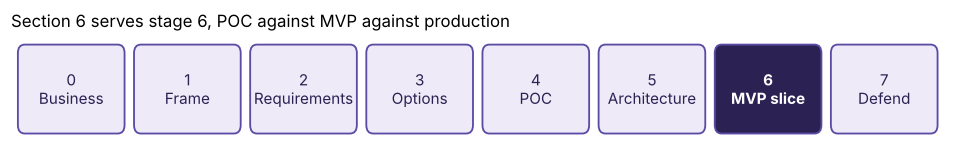

,What,What the POC proved,What an MVP adds,What production adds
0,The method,"On 9,000 held-out Taiwan cardholders the list ...",The same pipeline on Kalpa's first months of c...,"Runs itself monthly, retrains as outcomes arri..."
1,The split,A random split of one snapshot: every cardhold...,"An out-of-time test: train on earlier months, ...",A back-test every month against what actually ...
2,The cost,"Units, 1 to 5, set by Rohan.",Units priced in rupees by finance once the cal...,The ratio reviewed when costs move.
3,The user,A notebook and a demo function.,"One sheet to the collections team, with a reas...","Access control, an audit trail, and a named pe..."


In [26]:
ladder(6, "Section 6 serves stage 6, POC against MVP against production")
display(pd.DataFrame([
    ["The method", "On 9,000 held-out Taiwan cardholders the list costs 568 units per 1,000, against 779 for calling everyone and 1,106 for calling nobody.",
     "The same pipeline on Kalpa's first months of card data, scored once a month by a script.", "Runs itself monthly, retrains as outcomes arrive, alerts when the list size or the default rate jumps."],
    ["The split", "A random split of one snapshot: every cardholder shares the same six months.",
     "An out-of-time test: train on earlier months, test on the latest.", "A back-test every month against what actually happened."],
    ["The cost", "Units, 1 to 5, set by Rohan.", "Units priced in rupees by finance once the call centre runs.", "The ratio reviewed when costs move."],
    ["The user", "A notebook and a demo function.", "One sheet to the collections team, with a reason per call.", "Access control, an audit trail, and a named person who can stop the list."],
], columns=["What", "What the POC proved", "What an MVP adds", "What production adds"]))

In [27]:
date_cols = [c for c in cards.columns if "date" in c.lower()]
check("the file has no date column, so every cardholder shares one snapshot", date_cols == [])
check("every cardholder carries the same six statement months", all(c in cards.columns for c in BILLS + PAYS + STATUS))
print("The Taiwan score proves the pipeline and is never Kalpa's score.")
print("This data allows no out-of-time split, so the MVP must add one.")

PASS  the file has no date column, so every cardholder shares one snapshot
PASS  every cardholder carries the same six statement months
The Taiwan score proves the pipeline and is never Kalpa's score.
This data allows no out-of-time split, so the MVP must add one.


## 7. The cards: what does each card, and each Thursday twist, change?

**Who needs the answer.** The trainer at Thursday's gate, who hands each group its twist, and the
Saturday panel, which asks why a group holding another card chose differently.

**The questions on the way.** For each of the eight cards: what does the Tuesday rule change, what
does the twist change, and do the numbers match the research?

### Card 1: what happens when the CFO says a missed default costs 20 calls?

Tuesday: 5 to 1, threshold 0.16, bill 568. Thursday: 20 to 1. The theory threshold drops to 1/21 and
the model calls almost the whole book, so the model barely beats "call everyone".

In [28]:
t20 = 1 / 21
bill20 = error_bill(y_test, p_te >= t20, missed=20); every20 = error_bill(y_test, np.ones(len(y_test)), missed=20)
nobody20 = error_bill(y_test, np.zeros(len(y_test)), missed=20)
print(f"20 to 1: threshold {t20:.3f}, calls {np.mean(p_te >= t20):.1%}, bill {bill20:.0f}; call everyone {every20:.0f}; call nobody {nobody20:.0f}")
print(f"the model beats calling everyone by {100 * (round(every20) - round(bill20)) / round(every20):.1f} percent ({round(bill20)} against {round(every20)})")
check("card 1 twist: at 20 to 1 the model calls 97.7 percent and costs 765", near(np.mean(p_te >= t20), EXPECTED["c1_twist_share"], 0.002) and round(bill20) == EXPECTED["c1_twist_cost"])
check("card 1 twist: the model is only 1.8 percent under calling everyone (779)", round(every20) == EXPECTED["cost_everyone"] and near((every20 - bill20) / every20, 0.018, 0.002))

20 to 1: threshold 0.048, calls 97.7%, bill 765; call everyone 779; call nobody 4424
the model beats calling everyone by 1.8 percent (765 against 779)
PASS  card 1 twist: at 20 to 1 the model calls 97.7 percent and costs 765
PASS  card 1 twist: the model is only 1.8 percent under calling everyone (779)


### Card 2: when the team can make 1,000 calls, does the model beat the rule, and at 2,000?

Five-split means, because one split cannot settle a gap of a few percent: on seed 42 alone the gap
at 1,000 calls is 2 defaulters (676 against 674).

In [29]:
print(f"1,000 calls: model {FIVE.hgb_1000:.0f}, rule {FIVE.rule_1000:.0f}, gap {FIVE.hgb_1000 - FIVE.rule_1000:.0f}; random about {1000 * y.mean():.0f}")
print(f"2,000 calls: model {FIVE.hgb_2000:.0f}, rule {FIVE.rule_2000:.0f}, gap {FIVE.hgb_2000 - FIVE.rule_2000:.0f}")
print(f"seed 42 only, 1,000 calls: model {top_reach(y_test, p_hg, 1000)}, rule {top_reach(y_test, rule_key, 1000)}")
check("card 2: at 1,000 calls the model reaches 687 against the rule's 666", round(FIVE.hgb_1000) == EXPECTED["c2_model_1000"] and round(FIVE.rule_1000) == EXPECTED["c2_rule_1000"])
check("card 2 twist: at 2,000 calls the gap widens to about 69", round(FIVE.hgb_2000) == EXPECTED["c2_model_2000"] and abs(FIVE.rule_2000 - EXPECTED["c2_rule_2000"]) < 1)

1,000 calls: model 687, rule 666, gap 21; random about 221
2,000 calls: model 1079, rule 1010, gap 69
seed 42 only, 1,000 calls: model 676, rule 674
PASS  card 2: at 1,000 calls the model reaches 687 against the rule's 666
PASS  card 2 twist: at 2,000 calls the gap widens to about 69


### Card 3: when the team is paid on balance protected, which list wins?

Rank by chance times September's bill (negative bills clipped to zero) and compare with ranking by
chance alone, both at 1,000 calls.

In [30]:
bill_sept = np.clip(X_test["BILL_AMT1"].to_numpy(), 0, None)
owed = bill_sept[y_test == 1].sum()
out = {}
for name, s in [("chance alone", p_hg), ("chance times balance", p_hg * bill_sept)]:
    idx = np.argsort(-s)[:1000]
    out[name] = (int(y_test[idx].sum()), bill_sept[idx][y_test[idx] == 1].sum())
    print(f"{name:21s}: defaulters {out[name][0]}, defaulted balance NT$ {out[name][1] / 1e6:.1f}M of {owed / 1e6:.1f}M ({out[name][1] / owed:.1%})")
check("card 3: chance times balance protects 62.8 percent of defaulted balance with 469 defaulters",
      out["chance times balance"][0] == EXPECTED["c3_pbill_defaulters"] and near(out["chance times balance"][1] / owed, EXPECTED["c3_pbill_share"], 0.001))
check("card 3: chance alone protects 42.7 percent with 676 defaulters",
      out["chance alone"][0] == EXPECTED["c3_p_defaulters"] and near(out["chance alone"][1] / owed, EXPECTED["c3_p_share"], 0.001))

chance alone         : defaulters 676, defaulted balance NT$ 42.7M of 100.1M (42.7%)
chance times balance : defaulters 469, defaulted balance NT$ 62.9M of 100.1M (62.8%)
PASS  card 3: chance times balance protects 62.8 percent of defaulted balance with 469 defaulters
PASS  card 3: chance alone protects 42.7 percent with 676 defaulters


### Card 4: what does a written reason for every call cost?

A logistic regression's reasons can be read off its coefficients; gradient boosting needs the
score box's trick. Five-split means.

In [31]:
print(f"logistic, codes as categories {FIVE.lr_onehot_auc:.4f} | gradient boosting {FIVE.hgb_auc:.4f} | gap {FIVE.hgb_auc - FIVE.lr_onehot_auc:.4f}")
print(f"logistic, codes as numbers {FIVE.lr_raw_auc:.4f}: coding the statuses right is worth {FIVE.lr_onehot_auc - FIVE.lr_raw_auc:.3f}")
check("card 4: logistic with categories 0.765 against boosting 0.778", near(FIVE.lr_onehot_auc, EXPECTED["c4_lr_onehot"], 0.001) and near(FIVE.hgb_auc, EXPECTED["c4_hgb"], 0.001))
check("card 4: codes as numbers fall to 0.717, about four times the model gap", near(FIVE.lr_raw_auc, EXPECTED["c4_lr_raw"], 0.001)
      and (FIVE.lr_onehot_auc - FIVE.lr_raw_auc) > 3.5 * (FIVE.hgb_auc - FIVE.lr_onehot_auc))

logistic, codes as categories 0.7649 | gradient boosting 0.7779 | gap 0.0131
logistic, codes as numbers 0.7166: coding the statuses right is worth 0.048
PASS  card 4: logistic with categories 0.765 against boosting 0.778
PASS  card 4: codes as numbers fall to 0.717, about four times the model gap


### Card 5: does dropping sex, marital status, age and education change the list or the gap?

AUC is a five-split mean; the flag rates by group come from the seed-42 top-1,000 list.

In [32]:
m_ns = hgb().fit(X_train[NO_SENS], y_train); p_ns = m_ns.predict_proba(X_test[NO_SENS])[:, 1]
sex = X_test["SEX"].to_numpy(); table = []
for name, p in [("with the four columns", p_hg), ("without them", p_ns)]:
    flagged = np.zeros(len(y_test), bool); flagged[np.argsort(-p)[:1000]] = True
    table.append([name, f"{flagged[sex == 1].mean():.1%}", f"{flagged[sex == 2].mean():.1%}", int(y_test[flagged].sum())])
table.append(["true October default rate", f"{y_test[sex == 1].mean():.1%}", f"{y_test[sex == 2].mean():.1%}", ""])
display(pd.DataFrame(table, columns=["list", "men flagged", "women flagged", "defaulters reached"]))
print(f"five-split AUC: with {FIVE.hgb_auc:.4f}, without {FIVE.nosens_auc:.4f}")
check("card 5: dropping the four columns moves five-split AUC by about 0.001", near(FIVE.hgb_auc - FIVE.nosens_auc, 0.001, 0.0006))
check("card 5 twist: men are flagged more than women with and without the columns", all(float(r[1][:-1]) > float(r[2][:-1]) for r in table[:2]))
check("card 5 twist: flag rates match the research (11.5 and 10.9 with, 11.3 and 11.0 without)",
      [r[1] for r in table[:2]] == ["11.5%", "11.3%"] and [r[2] for r in table[:2]] == ["10.9%", "11.0%"])

,list,men flagged,women flagged,defaulters reached
0,with the four columns,11.5%,10.9%,676
1,without them,11.3%,11.0%,675
2,true October default rate,23.9%,21.0%,


five-split AUC: with 0.7779, without 0.7769
PASS  card 5: dropping the four columns moves five-split AUC by about 0.001
PASS  card 5 twist: men are flagged more than women with and without the columns
PASS  card 5 twist: flag rates match the research (11.5 and 10.9 with, 11.3 and 11.0 without)


### Card 6: what is lost when September's statement arrives after the list?

Drop September's status, bill and payment. The rule falls back to sorting by August's status. For a
group that already dropped September on Tuesday, the twist goes one month further (seed 42 only).

In [33]:
print(f"five-split AUC {FIVE.hgb_auc:.4f} -> {FIVE.lag_auc:.4f}; top 1,000: model {round(FIVE.lag_1000)}, rule by August {round(FIVE.lag_rule_1000)}, gap {round(FIVE.lag_1000) - round(FIVE.lag_rule_1000)}")
LAG2 = [c for c in LAG1 if c not in ("PAY_2", "BILL_AMT2", "PAY_AMT2")]
p_l2 = hgb().fit(X_train[LAG2], y_train).predict_proba(X_test[LAG2])[:, 1]
print(f"seed 42, two months of lag (no September, no August): AUC {roc_auc_score(y_test, p_l2):.4f}, top 1,000 reaches {top_reach(y_test, p_l2, 1000)}")
check("card 6: without September the five-split AUC falls to 0.747", near(FIVE.lag_auc, EXPECTED["c6_auc_lag"], 0.001))
check("card 6: the model's lead over the August rule grows to about 51", round(FIVE.lag_1000) == EXPECTED["c6_model_1000"] and round(FIVE.lag_rule_1000) == EXPECTED["c6_rule_1000"])

five-split AUC 0.7779 -> 0.7471; top 1,000: model 614, rule by August 563, gap 51


seed 42, two months of lag (no September, no August): AUC 0.7295, top 1,000 reaches 564
PASS  card 6: without September the five-split AUC falls to 0.747
PASS  card 6: the model's lead over the August rule grows to about 51


### Card 7: what does training on a stand-in label cost while October's outcome is unknown?

Train on April to August with September's lateness as the label, then score May to September and
judge against the true October default. The windows are relabelled so the most recent month is
always month 1.

In [34]:
d7 = cards.rename(columns={"PAY_0": "PAY_1"})
STATIC = ["LIMIT_BAL", "SEX", "EDUCATION", "MARRIAGE", "AGE"]
def window(start):
    out = d7[STATIC].copy()
    for j in range(5):
        i = start + j
        out[f"S{j + 1}"] = d7[f"PAY_{i}"]; out[f"B{j + 1}"] = d7[f"BILL_AMT{i}"]; out[f"P{j + 1}"] = d7[f"PAY_AMT{i}"]
    return out
tr_idx, te_idx = train_test_split(np.arange(len(d7)), test_size=TEST_SHARE, random_state=SEED, stratify=d7[TARGET])
X_old, X_new, y_oct = window(2), window(1), d7[TARGET].to_numpy()
res7 = {}
for k in (1, 2):
    y_sep = (d7["PAY_1"] >= k).astype(int).to_numpy()
    p = hgb().fit(X_old.iloc[tr_idx], y_sep[tr_idx]).predict_proba(X_new.iloc[te_idx])[:, 1]
    res7[f"proxy {k}"] = (roc_auc_score(y_oct[te_idx], p), top_reach(y_oct[te_idx], p, 1000), y_sep.mean())
p = hgb().fit(X_new.iloc[tr_idx], y_oct[tr_idx]).predict_proba(X_new.iloc[te_idx])[:, 1]
res7["true label"] = (roc_auc_score(y_oct[te_idx], p), top_reach(y_oct[te_idx], p, 1000), y_oct.mean())
display(pd.DataFrame(res7, index=["AUC on October", "defaulters in top 1,000", "label base rate"]).T.round(4))
check("card 7 twist: the stand-in label (September 1 or worse) scores 0.747 and reaches 539",
      near(res7["proxy 1"][0], EXPECTED["c7_proxy_auc"], 0.001) and res7["proxy 1"][1] == EXPECTED["c7_proxy_1000"])
check("card 7 twist: the true label scores 0.779 and reaches 680, so the stand-in costs 141 per 1,000 calls",
      near(res7["true label"][0], EXPECTED["c7_true_auc"], 0.001) and res7["true label"][1] - res7["proxy 1"][1] == 141)

,AUC on October,"defaulters in top 1,000",label base rate
proxy 1,0.7472,539.0,0.2273
proxy 2,0.6517,652.0,0.1043
true label,0.7790,680.0,0.2212


PASS  card 7 twist: the stand-in label (September 1 or worse) scores 0.747 and reaches 539
PASS  card 7 twist: the true label scores 0.779 and reaches 680, so the stand-in costs 141 per 1,000 calls


**What happened.** The stricter stand-in (September status 2 or worse) scores a lower AUC, about
0.652, yet reaches about 652 defaulters in the top 1,000: it ranks the very top well and the rest
badly. A group with a fixed 1,000 calls may prefer it, which is a good Saturday argument.

### Card 8: what moves when Rohan rules that an account owing nothing cannot default?

In [35]:
relabel = cards[TARGET].where(~zero, 0)
print(f"base rate as given {base:.4f} | relabel the {int(zero.sum())} accounts {relabel.mean():.4f} | remove them {cards.loc[~zero, TARGET].mean():.4f}")
print(f"those 299 defaults are {zero_def / n_def:.1%} of all {n_def:,} defaults")
print(f"call-nobody bill on the whole book: {1000 * base * COST_MISSED:.0f} as given, {1000 * relabel.mean() * COST_MISSED:.0f} after the ruling")
check("card 8 twist: relabelling drops the base rate to 21.1 percent", near(relabel.mean(), EXPECTED["c8_base_relabel"], 0.0006))
check("card 8 twist: removing the 795 accounts drops it to 21.7 percent", near(cards.loc[~zero, TARGET].mean(), EXPECTED["c8_base_removed"], 0.0006))
check("card 8: the 299 are 4.5 percent of all defaults", near(zero_def / n_def, 0.045, 0.0006))

base rate as given 0.2212 | relabel the 795 accounts 0.2112 | remove them 0.2170
those 299 defaults are 4.5% of all 6,636 defaults
call-nobody bill on the whole book: 1106 as given, 1056 after the ruling
PASS  card 8 twist: relabelling drops the base rate to 21.1 percent
PASS  card 8 twist: removing the 795 accounts drops it to 21.7 percent
PASS  card 8: the 299 are 4.5 percent of all defaults


### Does dropping the 35 exact repeats change any number?

The reference build keeps all 30,000 rows so the test book is the 9,000 card 2 names. This cell
measures what the other choice costs.

In [36]:
dedup = cards.drop_duplicates(subset=INPUTS + [TARGET])
Xd, yd = dedup[INPUTS], dedup[TARGET].to_numpy()
Xa, Xb, ya, yb = train_test_split(Xd, yd, test_size=TEST_SHARE, random_state=SEED, stratify=yd)
auc_d = roc_auc_score(yb, hgb().fit(Xa, ya).predict_proba(Xb)[:, 1])
print(f"rows {len(dedup):,}, test book {len(yb):,}, AUC {auc_d:.4f} against {auc['gradient boosting']:.4f} with every row")
check("dropping the 35 repeats moves AUC by less than 0.005", abs(auc_d - auc["gradient boosting"]) < 0.005)

rows 29,965, test book 8,990, AUC 0.7794 against 0.7789 with every row
PASS  dropping the 35 repeats moves AUC by less than 0.005


## 8. Every card on one page: which number does each group defend?

This table is the gate's crib: the Tuesday number, the Thursday number and where each was measured.

In [37]:
summary = pd.DataFrame([
    [1, "5 to 1: threshold 0.16, bill 568 against 779 (everyone) and 1,106 (nobody)", "20 to 1: calls 97.7%, bill 765, only 1.8% under everyone: change the action", "seed 42"],
    [2, f"1,000 calls: model {FIVE.hgb_1000:.0f}, rule {FIVE.rule_1000:.0f}", f"2,000 calls: model {FIVE.hgb_2000:.0f}, rule {FIVE.rule_2000:.0f}", "five splits"],
    [3, "balance protected is the team's measure", "chance x balance: 62.8% of balance, 469 defaulters; chance alone 42.7%, 676", "seed 42"],
    [4, "a reason for every call", f"in writing: logistic {FIVE.lr_onehot_auc:.3f} against boosting {FIVE.hgb_auc:.3f}; codes as numbers {FIVE.lr_raw_auc:.3f}", "five splits"],
    [5, "no sex, marital status, age or education", f"AUC {FIVE.hgb_auc:.4f} to {FIVE.nosens_auc:.4f}; flag rates by sex barely move, the gap stays", "five splits; seed 42 flags"],
    [6, "September arrives after the list", f"AUC {FIVE.hgb_auc:.3f} to {FIVE.lag_auc:.3f}; model {FIVE.lag_1000:.0f} against the August rule {FIVE.lag_rule_1000:.0f}", "five splits"],
    [7, "October's outcomes arrive in November", "stand-in label: AUC 0.747 and 539 reached, against 0.779 and 680: 141 fewer", "seed 42"],
    [8, "a code outside the dictionary is a question", "accounts owing nothing cannot default: base 22.1% to 21.1% (relabel) or 21.7% (remove)", "whole book"],
], columns=["card", "Tuesday", "Thursday's twist", "measured on"])
display(summary)
print(f"\n{TALLY['PASS']} checks passed, {TALLY['FAIL']} failed.")
check("every check in this notebook passed", TALLY["FAIL"] == 0)

,card,Tuesday,Thursday's twist,measured on
0,1,"5 to 1: threshold 0.16, bill 568 against 779 (...","20 to 1: calls 97.7%, bill 765, only 1.8% unde...",seed 42
1,2,"1,000 calls: model 687, rule 666","2,000 calls: model 1079, rule 1010",five splits
2,3,balance protected is the team's measure,"chance x balance: 62.8% of balance, 469 defaul...",seed 42
3,4,a reason for every call,in writing: logistic 0.765 against boosting 0....,five splits
4,5,"no sex, marital status, age or education",AUC 0.7779 to 0.7769; flag rates by sex barely...,five splits; seed 42 flags
5,6,September arrives after the list,AUC 0.778 to 0.747; model 614 against the Augu...,five splits
6,7,October's outcomes arrive in November,"stand-in label: AUC 0.747 and 539 reached, aga...",seed 42
7,8,a code outside the dictionary is a question,accounts owing nothing cannot default: base 22...,whole book



53 checks passed, 0 failed.
PASS  every check in this notebook passed


The breadcrumb notebook in the starter repository walks sections 1 to 6 with its hints sealed; this
notebook is its executed twin. When a group's number sits outside these, ask which split, which
threshold and which rows it used before you call it wrong.